# Probability Calibration and Final Validation

Objectives:
1. Compare original and calibrated churn models.
2. Evaluate calibration using Brier score and log loss.
3. Select a model using validation data.
4. Evaluate the selected approach on untouched test accounts.
5. Generate reproducible predictions for Snowflake.

The test set must not influence model selection.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    brier_score_loss, log_loss,
    roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier

df = pd.read_csv(
    "../data/raw/Case_Study_2_CLV_Predictive_Analytics.csv"
)

TARGET = "churn_event_next_12m"

FEATURES = [
    "current_capacity_tb",
    "utilization_rate_pct",
    "utilization_above_100_flag",
    "expansion_potential_signal"
]

labeled_df = df[df[TARGET].notna()].copy()
labeled_df["utilization_above_100_flag"] = (
    labeled_df["utilization_rate_pct"] > 1.0
).astype(int)

split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.30, random_state=42
)
tr_idx, temp_idx = next(
    split1.split(labeled_df, groups=labeled_df["account_id"])
)

train_df = labeled_df.iloc[tr_idx].copy()
temp_df = labeled_df.iloc[temp_idx].copy()

split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.50, random_state=42
)
v_idx, te_idx = next(
    split2.split(temp_df, groups=temp_df["account_id"])
)

val_df = temp_df.iloc[v_idx].copy()
test_df = temp_df.iloc[te_idx].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET].astype(int)
X_val = val_df[FEATURES]
y_val = val_df[TARGET].astype(int)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert set(train_df.account_id).isdisjoint(val_df.account_id)
assert set(train_df.account_id).isdisjoint(test_df.account_id)
assert set(val_df.account_id).isdisjoint(test_df.account_id)

Train: 1328
Validation: 280
Test: 276


In [7]:
def make_preprocessor():
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), [
            "current_capacity_tb",
            "utilization_rate_pct",
            "utilization_above_100_flag"
        ]),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), ["expansion_potential_signal"])
    ])

def make_rf():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=3,
            min_samples_leaf=20,
            random_state=42,
            n_jobs=-1
        ))
    ])

def make_xgb():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", XGBClassifier(
            n_estimators=150,
            max_depth=2,
            learning_rate=0.03,
            min_child_weight=10,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])

In [8]:
rf = make_rf()
xgb = make_xgb()

rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)

rf_prob = rf.predict_proba(X_val)[:, 1]
xgb_prob = xgb.predict_proba(X_val)[:, 1]

print("Uncalibrated models trained successfully.")

Uncalibrated models trained successfully.


In [9]:
group_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

calibration_folds = list(
    group_cv.split(
        X_train,
        y_train,
        groups=train_df["account_id"]
    )
)

# Verify account separation in every fold
groups = train_df["account_id"].to_numpy()

for fold, (fit_idx, cal_idx) in enumerate(calibration_folds, 1):
    assert set(groups[fit_idx]).isdisjoint(set(groups[cal_idx]))
    print(f"Fold {fold}: account separation verified")

Fold 1: account separation verified
Fold 2: account separation verified
Fold 3: account separation verified


In [11]:
rf_sigmoid = CalibratedClassifierCV(
    estimator=make_rf(),
    method="sigmoid",
    cv=calibration_folds,
    ensemble=True
)

rf_isotonic = CalibratedClassifierCV(
    estimator=make_rf(),
    method="isotonic",
    cv=calibration_folds,
    ensemble=True
)

rf_sigmoid.fit(X_train, y_train)
rf_isotonic.fit(X_train, y_train)

rf_sig_prob = rf_sigmoid.predict_proba(X_val)[:, 1]
rf_iso_prob = rf_isotonic.predict_proba(X_val)[:, 1]

print("Random Forest calibration completed.")

Random Forest calibration completed.


In [13]:
def evaluate(name, y, p):
    return {
        "Model": name,
        "Brier": brier_score_loss(y, p),
        "Log Loss": log_loss(y, p, labels=[0, 1]),
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Mean Predicted": p.mean(),
        "Observed": y.mean()
    }

p_static = np.full(len(y_val), 0.05)
p_prevalence = np.full(len(y_val), y_train.mean())

validation_results = pd.DataFrame([
    evaluate("Static 5%", y_val, p_static),
    evaluate("Training Prevalence", y_val, p_prevalence),
    evaluate("RF Core", y_val, rf_prob),
    evaluate("XGB Core", y_val, xgb_prob),
    evaluate("RF Sigmoid", y_val, rf_sig_prob),
    evaluate("RF Isotonic", y_val, rf_iso_prob)
])

display(
    validation_results.sort_values("Brier").round(4)
)

,Model,Brier,Log Loss,ROC-AUC,PR-AUC,Mean Predicted,Observed
1,Training Prevalence,0.1397,0.4526,0.5000,0.1679,0.1611,0.1679
2,RF Core,0.1401,0.4542,0.5322,0.1917,0.1626,0.1679
4,RF Sigmoid,0.1402,0.4543,0.4581,0.1596,0.1602,0.1679
3,XGB Core,0.1402,0.4547,0.5231,0.1856,0.1603,0.1679
5,RF Isotonic,0.1408,0.4547,0.5498,0.1814,0.1622,0.1679
0,Static 5%,0.1536,0.5455,0.5000,0.1679,0.0500,0.1679


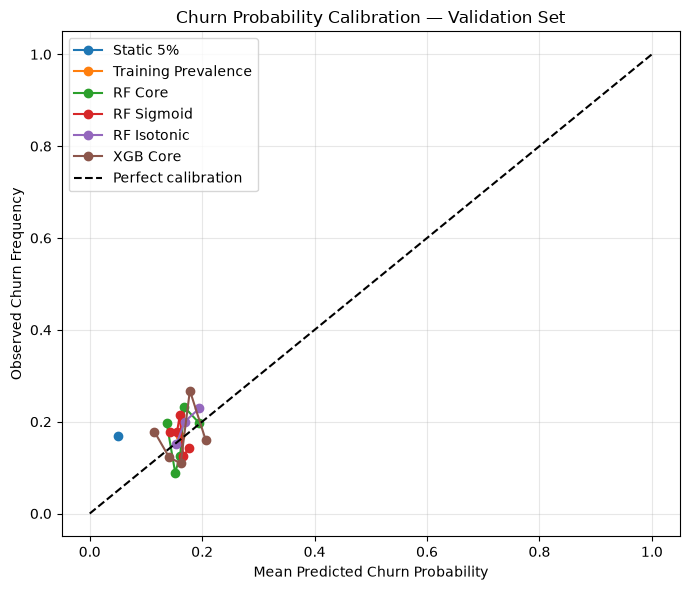

In [14]:
plt.figure(figsize=(7, 6))

models_to_plot = {
    "Static 5%": p_static,
    "Training Prevalence": p_prevalence,
    "RF Core": rf_prob,
    "RF Sigmoid": rf_sig_prob,
    "RF Isotonic": rf_iso_prob,
    "XGB Core": xgb_prob
}

for name, probabilities in models_to_plot.items():
    observed, predicted = calibration_curve(
        y_val,
        probabilities,
        n_bins=5,
        strategy="quantile"
    )
    plt.plot(predicted, observed, marker="o", label=name)

plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Observed Churn Frequency")
plt.title("Churn Probability Calibration — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Calibration and Model Selection — Findings

Six approaches were compared using the account-grouped validation set.

The training-prevalence baseline achieved the lowest Brier score (0.1397) and log loss (0.4526).

The uncalibrated Random Forest achieved a Brier score of 0.1401, while sigmoid and isotonic calibration did not improve its probability accuracy.

The results suggest that the available features provide limited additional predictive information beyond the overall observed churn rate.

**Model selection:** The training-prevalence baseline is selected as the best validated probability estimator. Random Forest Core and XGBoost Core are retained as machine learning comparators.

These conclusions are based on validation results. Final generalization performance will be assessed on the untouched test set.

## 5.1 — Final Holdout Test Evaluation

The final modeling approach was selected using training
cross-validation and validation results.

The test set contains accounts not present in the training
or validation partitions.

No additional model selection or hyperparameter tuning
will be performed using test results.

In [15]:
# Prepare untouched test features and labels
test_features = test_df.copy()

test_features["utilization_above_100_flag"] = (
    test_features["utilization_rate_pct"] > 1.0
).astype(int)

X_test = test_features[FEATURES]
y_test = test_features[TARGET].astype(int)

print("Test rows:", len(X_test))
print("Test accounts:", test_df["account_id"].nunique())

Test rows: 276
Test accounts: 150


In [16]:
# Baselines
test_static_prob = np.full(len(y_test), 0.05)
test_prevalence_prob = np.full(
    len(y_test),
    y_train.mean()
)

# Previously trained ML models
test_rf_prob = rf.predict_proba(X_test)[:, 1]
test_xgb_prob = xgb.predict_proba(X_test)[:, 1]

print("All test predictions generated.")

All test predictions generated.


In [17]:
test_results = pd.DataFrame([
    evaluate("Static 5%", y_test, test_static_prob),
    evaluate("Training Prevalence", y_test, test_prevalence_prob),
    evaluate("Random Forest Core", y_test, test_rf_prob),
    evaluate("XGBoost Core", y_test, test_xgb_prob)
])

display(test_results.sort_values("Brier").round(4))

,Model,Brier,Log Loss,ROC-AUC,PR-AUC,Mean Predicted,Observed
1,Training Prevalence,0.1168,0.3969,0.5000,0.1341,0.1611,0.1341
2,Random Forest Core,0.1174,0.3984,0.5199,0.1449,0.1653,0.1341
3,XGBoost Core,0.1179,0.4003,0.5155,0.1450,0.1639,0.1341
0,Static 5%,0.1232,0.4460,0.5000,0.1341,0.0500,0.1341


In [18]:
test_results["Forecast Bias (pp)"] = (
    test_results["Mean Predicted"] -
    test_results["Observed"]
) * 100

display(test_results.round(4))

,Model,Brier,Log Loss,ROC-AUC,PR-AUC,Mean Predicted,Observed,Forecast Bias (pp)
0,Static 5%,0.1232,0.4460,0.5000,0.1341,0.0500,0.1341,-8.4058
1,Training Prevalence,0.1168,0.3969,0.5000,0.1341,0.1611,0.1341,2.7087
2,Random Forest Core,0.1174,0.3984,0.5199,0.1449,0.1653,0.1341,3.1212
3,XGBoost Core,0.1179,0.4003,0.5155,0.1450,0.1639,0.1341,2.9879


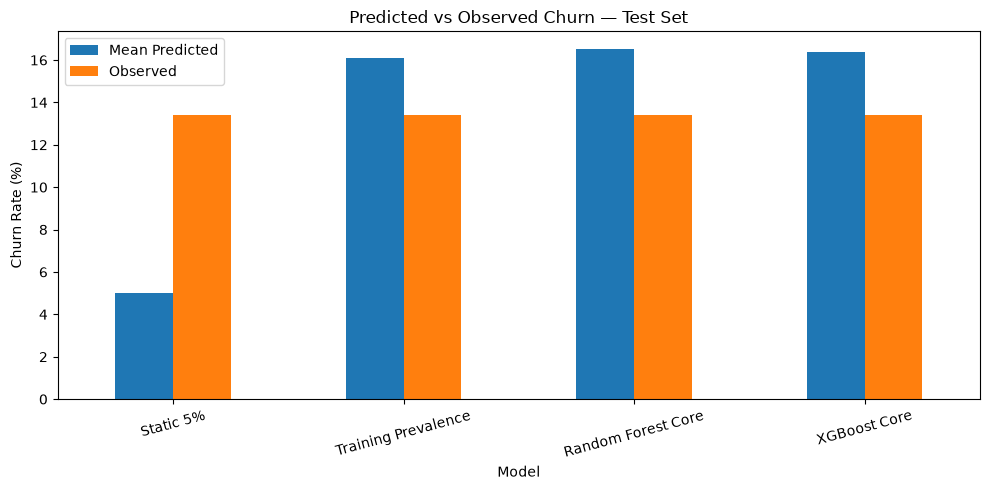

In [19]:
comparison = test_results[
    ["Model", "Mean Predicted", "Observed"]
].copy()

comparison[["Mean Predicted", "Observed"]] *= 100

ax = comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    rot=15
)

ax.set_ylabel("Churn Rate (%)")
ax.set_title("Predicted vs Observed Churn — Test Set")

plt.tight_layout()
plt.show()

In [20]:
from pathlib import Path
from datetime import datetime, timezone

MODEL_VERSION = "v1_20261011"

scored_df = test_df[
    ["account_id", "array_id"]
].copy()

scored_df["baseline_churn_probability"] = 0.05
scored_df["prevalence_churn_probability"] = test_prevalence_prob
scored_df["rf_churn_probability"] = test_rf_prob
scored_df["xgb_churn_probability"] = test_xgb_prob

# Selected production-style score
scored_df["churn_probability_12m"] = test_prevalence_prob

scored_df["risk_bucket"] = pd.cut(
    scored_df["churn_probability_12m"],
    bins=[-0.001, 0.10, 0.20, 1.0],
    labels=["LOW", "MEDIUM", "HIGH"]
).astype(str)

scored_df["model_version"] = MODEL_VERSION
scored_df["scored_at_utc"] = datetime.now(timezone.utc).isoformat()

output_path = Path("../outputs")
output_path.mkdir(parents=True, exist_ok=True)

scored_df.to_csv(
    output_path / "clv_scored_output.csv",
    index=False
)

display(scored_df.head())

print("Export complete.")

,account_id,array_id,baseline_churn_probability,prevalence_churn_probability,rf_churn_probability,xgb_churn_probability,churn_probability_12m,risk_bucket,model_version,scored_at_utc
7,ACC_1007,ARR_5007,0.05,0.161145,0.172526,0.171670,0.161145,MEDIUM,v1_20261011,2026-10-11T06:01:06.693727+00:00
23,ACC_1023,ARR_5023,0.05,0.161145,0.171110,0.206658,0.161145,MEDIUM,v1_20261011,2026-10-11T06:01:06.693727+00:00
25,ACC_1025,ARR_5025,0.05,0.161145,0.150190,0.121229,0.161145,MEDIUM,v1_20261011,2026-10-11T06:01:06.693727+00:00
29,ACC_1029,ARR_5029,0.05,0.161145,0.154341,0.170336,0.161145,MEDIUM,v1_20261011,2026-10-11T06:01:06.693727+00:00
31,ACC_1031,ARR_5031,0.05,0.161145,0.150859,0.172182,0.161145,MEDIUM,v1_20261011,2026-10-11T06:01:06.693727+00:00


Export complete.


In [21]:
print("Exported rows:", len(scored_df))
print("Unique arrays:", scored_df["array_id"].nunique())

print("\nMissing values:")
print(scored_df.isna().sum())

print("\nRisk bucket distribution:")
print(scored_df["risk_bucket"].value_counts())

assert scored_df["array_id"].is_unique

assert scored_df[
    "churn_probability_12m"
].between(0, 1).all()

print("\nPASS: Scored output verification successful.")

Exported rows: 276
Unique arrays: 276

Missing values:
account_id                      0
array_id                        0
baseline_churn_probability      0
prevalence_churn_probability    0
rf_churn_probability            0
xgb_churn_probability           0
churn_probability_12m           0
risk_bucket                     0
model_version                   0
scored_at_utc                   0
dtype: int64

Risk bucket distribution:
risk_bucket
MEDIUM    276
Name: count, dtype: int64

PASS: Scored output verification successful.
